<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS11/JS11_LAB1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import zipfile

print("Ukuran file:", os.path.getsize('dataset.zip') / (1024**2), "MB")
print("ZIP valid:", zipfile.is_zipfile('dataset.zip'))

!file dataset.zip

Ukuran file: 221.79411220550537 MB
ZIP valid: True
dataset.zip: Zip archive data, at least v2.0 to extract, compression method=store


In [4]:
import zipfile

with zipfile.ZipFile('dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

print("Dataset berhasil diekstrak!")

Dataset berhasil diekstrak!


In [5]:
!ls dataset

single_prediction  test_set  training_set


In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [7]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

training_set = train_datagen.flow_from_directory(
    'dataset/training_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

Found 8000 images belonging to 2 classes.


In [8]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_set = test_datagen.flow_from_directory(
    'dataset/test_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

Found 2000 images belonging to 2 classes.


In [9]:
print("Jumlah data training:", training_set.samples)
print("Jumlah data testing:", test_set.samples)
print("Label kelas:", training_set.class_indices)

Jumlah data training: 8000
Jumlah data testing: 2000
Label kelas: {'cats': 0, 'dogs': 1}


In [10]:
cnn = tf.keras.models.Sequential()

In [11]:
cnn.add(tf.keras.layers.Input(shape=(64, 64, 3)))

cnn.add(tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=3,
    activation='relu'
))

In [12]:
cnn.add(tf.keras.layers.MaxPool2D(
    pool_size=2,
    strides=2
))

In [13]:
cnn.add(tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=3,
    activation='relu'
))

cnn.add(tf.keras.layers.MaxPool2D(
    pool_size=2,
    strides=2
))

In [14]:
cnn.add(tf.keras.layers.Flatten())

In [15]:
cnn.add(tf.keras.layers.Dense(
    units=128,
    activation='relu'
))

In [16]:
cnn.add(tf.keras.layers.Dense(
    units=1,
    activation='sigmoid'
))

In [17]:
cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [18]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = cnn.fit(
    x=training_set,
    validation_data=test_set,
    epochs=25
)

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 86s 339ms/step - accuracy: 0.5869 - loss: 0.6685 - val_accuracy: 0.6595 - val_loss: 0.6220
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 67s 266ms/step - accuracy: 0.6758 - loss: 0.6000 - val_accuracy: 0.6800 - val_loss: 0.6041
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 67s 268ms/step - accuracy: 0.7032 - loss: 0.5570 - val_accuracy: 0.7160 - val_loss: 0.5673
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 262ms/step - accuracy: 0.7406 - loss: 0.5270 - val_accuracy: 0.7475 - val_loss: 0.5042
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 64s 257ms/step - accuracy: 0.7473 - loss: 0.5065 - val_accuracy: 0.7565 - val_loss: 0.5127
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 263ms/step - accuracy: 0.7728 - loss: 0.4776 - val_accuracy: 0.7685 - val_loss: 0.4954
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 262ms/step - accuracy: 0.7765 - loss: 0.4690 - val_accuracy: 0.7785 - val_loss: 0.4785
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 263ms/step - accuracy: 0.7884 - loss: 0

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

test_image = load_img(
    'dataset/single_prediction/cat_or_dog_1.jpg',
    target_size=(64, 64)
)

original_image = test_image

test_image = img_to_array(test_image)
test_image = test_image / 255.0
test_image = np.expand_dims(test_image, axis=0)

result = cnn.predict(test_image)

print("Label kelas:", training_set.class_indices)

if result[0][0] > 0.5:
    prediction = 'dog'
else:
    prediction = 'cat'


print("Hasil prediksi:", prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Label kelas: {'cats': 0, 'dogs': 1}
Hasil prediksi: dog


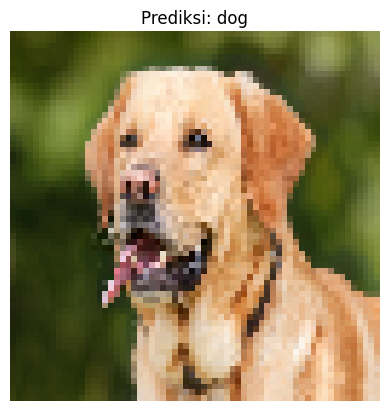

In [21]:
plt.imshow(original_image)
plt.title(f"Prediksi: {prediction}")
plt.axis('off')
plt.show()